# Bike flows (V2) – Rush-hour maps (same style as traffic flows)

This notebook:
- Loads bike edges (geometries) and bike flows (edge × datetime/hour).
- Joins flows ↔ geometries using (u, v, key).
- Aggregates into 3 rush-hour periods for a *typical day*:
  1) Sum hours within each date (per edge, per period)
  2) Mean across all dates (per edge, per period)
- Plots 3 maps side-by-side with OSM basemap:
  - Morning (06–10)
  - Midday (11–15)
  - Evening (16–20)
Encoding:
- Color = flow intensity (period-specific scaling across the 3 plots)
- Line width = flow intensity


In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import Normalize

import contextily as ctx


In [10]:
# --- Set these paths ---
EDGES_PATH = "../AWS/containers/local_bucket/gold/zurich_pedbike_flows/2025/V2_bike_edges.parquet"
FLOWS_PATH = "../AWS/containers/local_bucket/gold/zurich_pedbike_flows/2025/V2_bike_flows.parquet"

# Choose which flow column to plot
FLOW_COL = "flow"       # or "flow_norm"

# Time windows
MORNING_HOURS = list(range(6, 11))   # 06–10
MIDDAY_HOURS  = list(range(11, 16))  # 11–15
EVENING_HOURS = list(range(16, 21))  # 16–20

HOUR_COL = "hour"
EDGE_ID_COL = "edge_id"


In [11]:
edges = gpd.read_parquet(EDGES_PATH)
flows = pd.read_parquet(FLOWS_PATH)

print("Edges:", edges.shape, "CRS:", edges.crs)
print("Flows:", flows.shape)

print("\nEdges columns:", list(edges.columns))
print("Flows columns:", list(flows.columns))

display(edges.head())
display(flows.head())

# Ensure hour is integer
flows[HOUR_COL] = flows[HOUR_COL].astype(int)


Edges: (44861, 2) CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "CH1903+ / LV95", "base_crs": {"name": "CH1903+", "datum": {"type": "GeodeticReferenceFrame", "name": "CH1903+", "ellipsoid": {"name": "Bessel 1841", "semi_major_axis": 6377397.155, "inverse_flattening": 299.1528128}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degree"}]}, "id": {"authority": "EPSG", "code": 4150}}, "conversion": {"name": "Swiss Oblique Mercator 1995", "method": {"name": "Hotine Oblique Mercator (variant B)", "id": {"authority": "EPSG", "code": 9815}}, "parameters": [{"name": "Latitude of projection centre", "value": 46.9524055555556, "unit": "degree", "id": {"authority": "EPSG", "code": 8811}}, {"name": "Longitude of projection centre", "value": 7.4395833333333

,edge_id,geometry
0,1,"LINESTRING (2680796.689 1248849.282, 2680817.3..."
1,2,"LINESTRING (2680796.689 1248849.282, 2680795.6..."
2,3,"LINESTRING (2680776.828 1248799.964, 2680771.3..."
3,4,"LINESTRING (2680776.828 1248799.964, 2680759.2..."
4,5,"LINESTRING (2680776.828 1248799.964, 2680782.8..."


,edge_id,hour,flow,flow_norm
0,41,0,5.073846,0.041745
1,9732,0,0.917254,0.007547
2,38701,0,0.917254,0.007547
3,1973,0,11.135809,0.091619
4,1352,0,7.981628,0.065668


In [12]:
def aggregate_period(flows_df, hours, edge_id_col, hour_col, flow_col, agg="sum"):
    subset = flows_df[flows_df[hour_col].isin(hours)].copy()
    if subset.empty:
        raise ValueError(f"No rows found for hours {hours}")

    if agg == "sum":
        out = subset.groupby(edge_id_col, as_index=False)[flow_col].sum()
    elif agg == "mean":
        out = subset.groupby(edge_id_col, as_index=False)[flow_col].mean()
    else:
        raise ValueError("agg must be 'sum' or 'mean'")
    return out

morning = aggregate_period(flows, MORNING_HOURS, EDGE_ID_COL, HOUR_COL, FLOW_COL, agg="sum")
midday  = aggregate_period(flows, MIDDAY_HOURS,  EDGE_ID_COL, HOUR_COL, FLOW_COL, agg="sum")
evening = aggregate_period(flows, EVENING_HOURS, EDGE_ID_COL, HOUR_COL, FLOW_COL, agg="sum")

morning = morning.rename(columns={FLOW_COL: "flow_period"})
midday  = midday.rename(columns={FLOW_COL: "flow_period"})
evening = evening.rename(columns={FLOW_COL: "flow_period"})

print("Morning:", morning.shape, "Midday:", midday.shape, "Evening:", evening.shape)
display(morning.head())


Morning: (245, 2) Midday: (185, 2) Evening: (253, 2)


,edge_id,flow_period
0,41,146.618462
1,142,5.344122
2,182,121.557780
3,183,150.112150
4,753,105.791703


In [13]:
gdf_morning = edges.merge(morning, on=EDGE_ID_COL, how="left")
gdf_midday  = edges.merge(midday,  on=EDGE_ID_COL, how="left")
gdf_evening = edges.merge(evening, on=EDGE_ID_COL, how="left")

for g in (gdf_morning, gdf_midday, gdf_evening):
    g["flow_period"] = g["flow_period"].fillna(0.0)

print(gdf_morning.shape, gdf_midday.shape, gdf_evening.shape)


(44861, 3) (44861, 3) (44861, 3)


In [14]:
flows_3 = pd.concat([
    gdf_morning["flow_period"],
    gdf_midday["flow_period"],
    gdf_evening["flow_period"],
])

max_flow_3 = flows_3.max()
min_flow_3 = flows_3.min()

print(f"Aggregated period flow range: {min_flow_3:.2f} – {max_flow_3:.2f}")

norm_3 = Normalize(vmin=0, vmax=max_flow_3)
cmap_3 = plt.cm.viridis

BASE_LW_3 = 0.2
MAX_EXTRA_LW_3 = 3.0


Aggregated period flow range: 0.00 – 450.54


In [15]:
gdf_morning_3857 = gdf_morning.to_crs(epsg=3857)
gdf_midday_3857  = gdf_midday.to_crs(epsg=3857)
gdf_evening_3857 = gdf_evening.to_crs(epsg=3857)


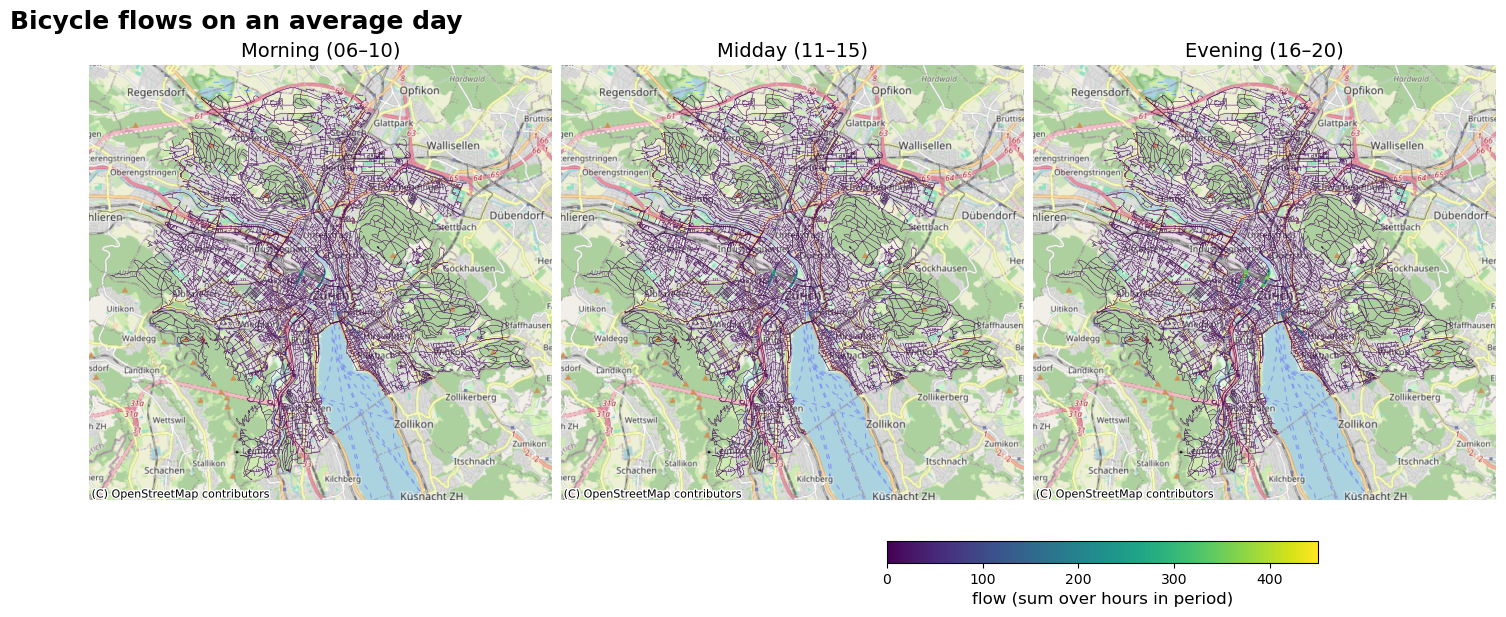

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

periods = [
    ("Morning (06–10)", gdf_morning_3857),
    ("Midday (11–15)", gdf_midday_3857),
    ("Evening (16–20)", gdf_evening_3857),
]

for ax, (title, gdf_agg) in zip(axes.flat, periods):
    vals = gdf_agg["flow_period"].values

    lw = BASE_LW_3 + MAX_EXTRA_LW_3 * (vals / max_flow_3 if max_flow_3 > 0 else 0)
    colors = cmap_3(norm_3(vals))

    gdf_agg.plot(
        ax=ax,
        color=colors,
        linewidth=lw,
        zorder=2,
    )

    ctx.add_basemap(
        ax,
        source=ctx.providers.OpenStreetMap.Mapnik,
        crs=gdf_agg.crs,
        zorder=1,
    )

    ax.set_title(title, fontsize=14)
    ax.set_axis_off()
    ax.set_aspect("equal")

# Shared colorbar
sm = mpl.cm.ScalarMappable(norm=norm_3, cmap=cmap_3)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes.ravel().tolist(),
    orientation="horizontal",
    fraction=0.04,
    pad=0.10,
)
cbar.set_label(f"{FLOW_COL} (sum over hours in period)", fontsize=12)

plt.subplots_adjust(
    left=0.03,
    right=0.7,
    top=0.90,
    bottom=0.2,
    wspace=0.02,
)

plt.suptitle(
    "Bicycle flows on an average day",
    fontsize=18,
    fontweight="bold",
    y=0.9,
    x=0.1
)


plt.show()


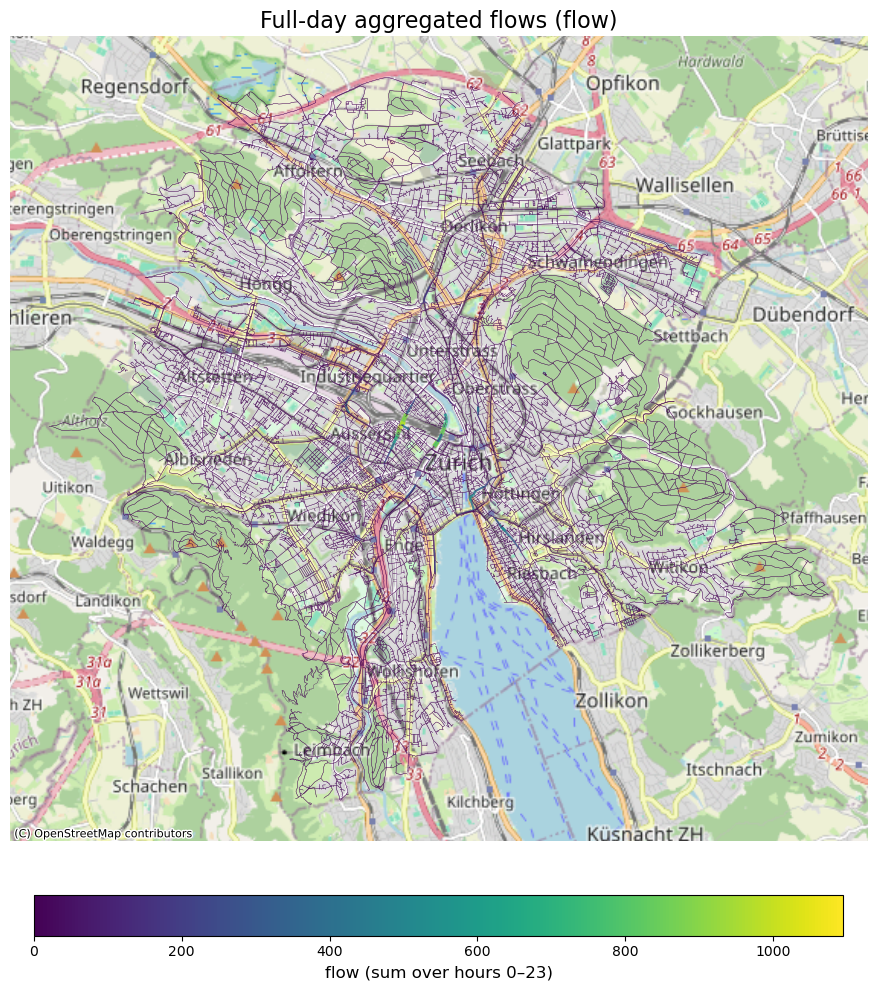

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import Normalize
import contextily as ctx

# -----------------------------
# Settings you can change
# -----------------------------
FLOW_COL = "flow"       # or "flow_norm"
EDGE_ID_COL = "edge_id"
HOUR_COL = "hour"

# Styling
BASE_LW = 0.25
MAX_EXTRA_LW = 3.5
CMAP = plt.cm.viridis

# Robust scaling (optional but recommended)
Q_LO, Q_HI = 0.02, 0.98

# -----------------------------
# 1) Aggregate full day (sum over all hours)
# -----------------------------
flows_full_day = (
    flows
    .groupby(EDGE_ID_COL, as_index=False)[FLOW_COL]
    .sum()
    .rename(columns={FLOW_COL: "flow_day"})
)

# -----------------------------
# 2) Join to geometries
# -----------------------------
gdf_day = edges.merge(flows_full_day, on=EDGE_ID_COL, how="left")
gdf_day["flow_day"] = gdf_day["flow_day"].fillna(0.0)

# -----------------------------
# 3) Reproject for OSM basemap
# -----------------------------
gdf_day_3857 = gdf_day.to_crs(epsg=3857)

# -----------------------------
# 4) Build per-plot scaling (quantile clip)
# -----------------------------
vals = gdf_day_3857["flow_day"].astype(float).values
lo = np.nanquantile(vals, Q_LO)
hi = np.nanquantile(vals, Q_HI)
if hi <= lo:
    hi = max(lo + 1e-9, np.nanmax(vals))

norm = Normalize(vmin=lo, vmax=hi)

# linewidth + color
vals_clip = np.clip(vals, lo, hi)
lw = BASE_LW + MAX_EXTRA_LW * ((vals_clip - lo) / max(hi - lo, 1e-9))
colors = CMAP(norm(vals_clip))

# -----------------------------
# 5) Plot
# -----------------------------
fig, ax = plt.subplots(1, 1, figsize=(14, 10))

gdf_day_3857.plot(
    ax=ax,
    color=colors,
    linewidth=lw,
    alpha=0.85,
    zorder=2,
)

ctx.add_basemap(
    ax,
    source=ctx.providers.OpenStreetMap.Mapnik,
    crs=gdf_day_3857.crs,
    zorder=1,
)

ax.set_axis_off()
ax.set_aspect("equal")
ax.set_title(f"Full-day aggregated flows ({FLOW_COL})", fontsize=16)

# Colorbar
sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    fraction=0.045,
    pad=0.06,
)
cbar.set_label(f"{FLOW_COL} (sum over hours 0–23)", fontsize=12)

plt.tight_layout()
plt.show()


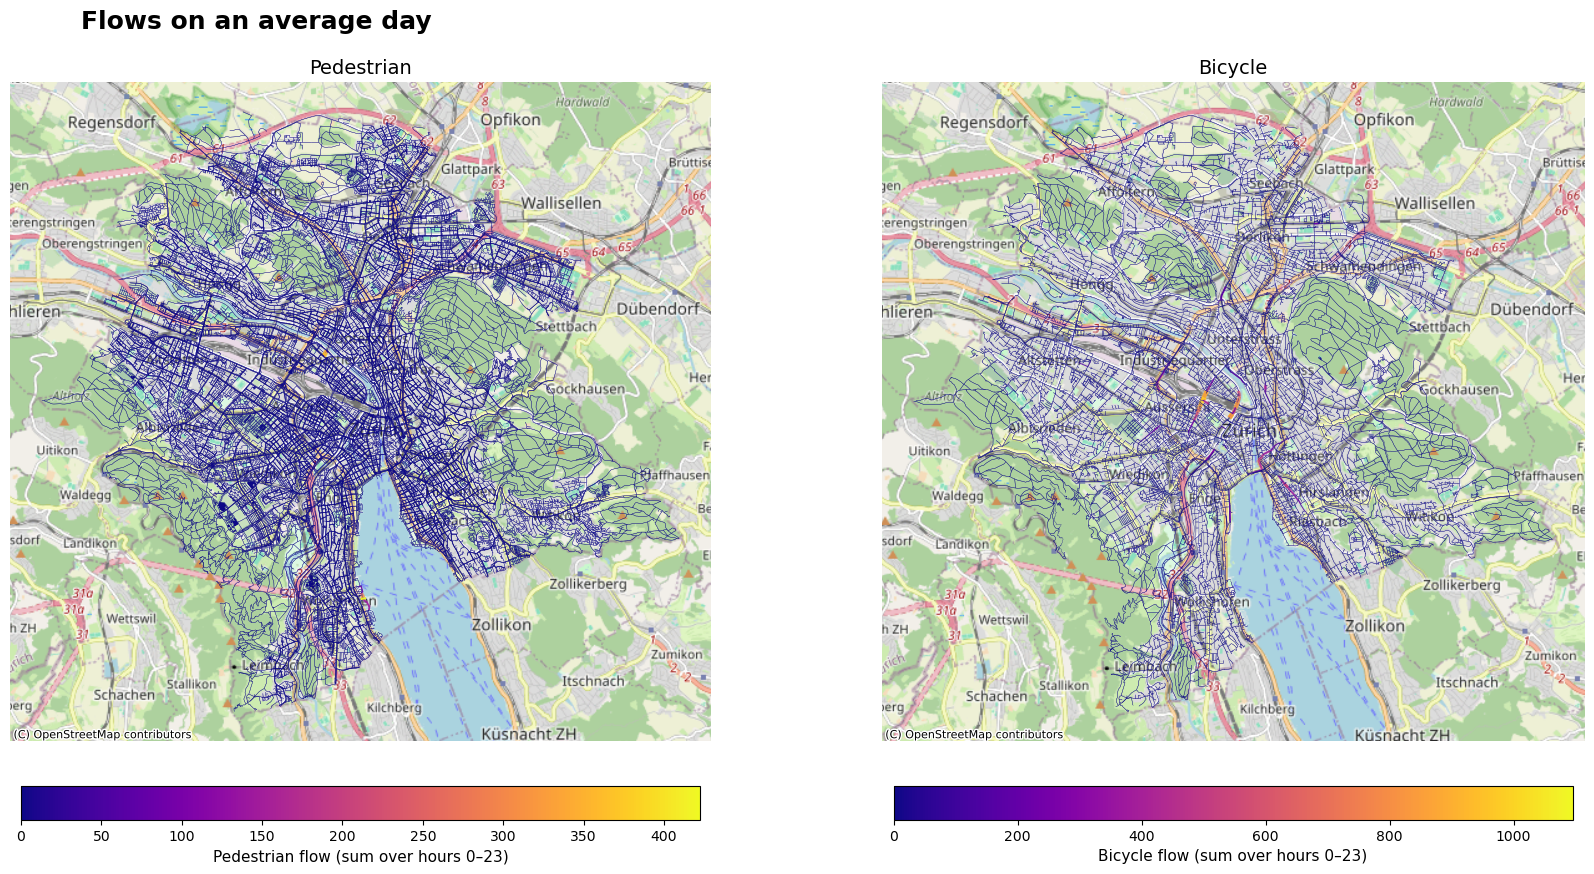

In [25]:
# --- Two-panel static map: full-day aggregated Pedestrian vs Bicycle (V2 schema) ---

import pandas as pd
import geopandas as gpd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import Normalize
import contextily as ctx

# -----------------------------
# Paths
# -----------------------------
PED_EDGES_PATH  = "../AWS/containers/local_bucket/gold/zurich_pedbike_flows/2025/V2_ped_edges.parquet"
PED_FLOWS_PATH  = "../AWS/containers/local_bucket/gold/zurich_pedbike_flows/2025/V2_ped_flows.parquet"

BIKE_EDGES_PATH = "../AWS/containers/local_bucket/gold/zurich_pedbike_flows/2025/V2_bike_edges.parquet"
BIKE_FLOWS_PATH = "../AWS/containers/local_bucket/gold/zurich_pedbike_flows/2025/V2_bike_flows.parquet"

# -----------------------------
# Config you might change
# -----------------------------
EDGE_ID_COL = "edge_id"
FLOW_COL = "flow"       # or "flow_norm"
HOUR_COL = "hour"       # present but we aggregate across all hours

# Styling
CMAP_PED  = plt.cm.plasma
CMAP_BIKE = plt.cm.plasma

BASE_LW = 0.25
MAX_EXTRA_LW = 3.5

# Robust scaling per panel (recommended)
Q_LO, Q_HI = 0.02, 0.98

# -----------------------------
# Helpers
# -----------------------------
def load_and_aggregate_full_day(edges_path, flows_path, edge_id_col, flow_col):
    edges = gpd.read_parquet(edges_path)
    flows = pd.read_parquet(flows_path)

    # Ensure numeric
    flows[flow_col] = pd.to_numeric(flows[flow_col], errors="coerce").fillna(0.0)

    # Full-day aggregation (sum over all hours)
    flows_day = (
        flows.groupby(edge_id_col, as_index=False)[flow_col]
        .sum()
        .rename(columns={flow_col: "flow_day"})
    )

    gdf_day = edges.merge(flows_day, on=edge_id_col, how="left")
    gdf_day["flow_day"] = gdf_day["flow_day"].fillna(0.0)

    if gdf_day.crs is None:
        raise ValueError(f"CRS is None for {edges_path}. Please set CRS before plotting.")

    return gdf_day

def compute_norm(vals, q_lo=0.02, q_hi=0.98):
    vals = np.asarray(vals, dtype=float)
    lo = np.nanquantile(vals, q_lo)
    hi = np.nanquantile(vals, q_hi)
    if not np.isfinite(lo):
        lo = 0.0
    if not np.isfinite(hi) or hi <= lo:
        hi = max(lo + 1e-9, np.nanmax(vals) if np.isfinite(np.nanmax(vals)) else lo + 1.0)
    return lo, hi, Normalize(vmin=lo, vmax=hi)

def plot_panel(ax, gdf_3857, cmap, title):
    vals = gdf_3857["flow_day"].astype(float).values
    lo, hi, norm = compute_norm(vals, Q_LO, Q_HI)

    vals_clip = np.clip(vals, lo, hi)
    lw = BASE_LW + MAX_EXTRA_LW * ((vals_clip - lo) / max(hi - lo, 1e-9))
    colors = cmap(norm(vals_clip))

    gdf_3857.plot(
        ax=ax,
        color=colors,
        linewidth=lw,
        alpha=0.85,
        zorder=2,
    )

    ctx.add_basemap(
        ax,
        source=ctx.providers.OpenStreetMap.Mapnik,
        crs=gdf_3857.crs,
        zorder=1,
    )

    ax.set_title(title, fontsize=14)
    ax.set_axis_off()
    ax.set_aspect("equal")

    # colorbar for this panel (separate scales!)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    return sm

# -----------------------------
# Load + aggregate
# -----------------------------
ped_day  = load_and_aggregate_full_day(PED_EDGES_PATH,  PED_FLOWS_PATH,  EDGE_ID_COL, FLOW_COL)
bike_day = load_and_aggregate_full_day(BIKE_EDGES_PATH, BIKE_FLOWS_PATH, EDGE_ID_COL, FLOW_COL)

# Reproject to 3857 for OSM tiles
ped_3857  = ped_day.to_crs(epsg=3857)
bike_3857 = bike_day.to_crs(epsg=3857)

# -----------------------------
# Plot 2 maps side-by-side
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

sm_ped  = plot_panel(axes[0], ped_3857,  CMAP_PED,  f"Pedestrian")
sm_bike = plot_panel(axes[1], bike_3857, CMAP_BIKE, f"Bicycle")

# Add two separate colorbars below each subplot (so scales stay correct)
cbar1 = fig.colorbar(sm_ped,  ax=axes[0], orientation="horizontal", fraction=0.046, pad=0.06)
cbar1.set_label(f"Pedestrian {FLOW_COL} (sum over hours 0–23)", fontsize=11)

cbar2 = fig.colorbar(sm_bike, ax=axes[1], orientation="horizontal", fraction=0.046, pad=0.06)
cbar2.set_label(f"Bicycle {FLOW_COL} (sum over hours 0–23)", fontsize=11)

plt.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.10, wspace=0.02)

plt.suptitle(
    "Flows on an average day",
    fontsize=18,
    fontweight="bold",
    y=1,
    x=0.2
)


plt.show()
